# Entrenamiento V2: factorización matricial colaborativa

Este notebook documenta el entrenamiento final V2. Reutiliza la arquitectura V1: `mu + b_u + b_i + p_u dot q_i`. La ejecución prolongada está desacoplada en `src/ml/train_collaborative.py`; aquí se inspeccionan los resultados persistidos. No se usa `test.parquet` para selección.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / 'artifacts' / 'v2').exists(): ROOT = ROOT.parent.parent
ARTIFACTS = ROOT / 'artifacts' / 'v2' / 'collaborative_mf'
ML = ROOT / 'data' / 'ml_v2'
metrics = json.loads((ARTIFACTS / 'metrics.json').read_text(encoding='utf-8'))
config = json.loads((ARTIFACTS / 'config.json').read_text(encoding='utf-8'))
history = pd.read_csv(ARTIFACTS / 'training_history.csv')
display(pd.DataFrame(metrics.items(), columns=['métrica', 'valor']))
display(history[['epoch', 'train_mse', 'valid_mse', 'valid_mae', 'valid_rmse', 'epoch_seconds']])


,métrica,valor
0,selection_split,valid
1,test_used,False
2,baseline_global_mean_valid,"{'mse': 0.9387730518671378, 'mae': 0.748260278..."
3,matrix_factorization_valid,"{'mse': 0.83022976380977, 'mae': 0.72071394479..."
4,best_epoch,10
5,best_valid_mse,0.83023
6,epochs_executed,12
7,stop_reason,max_epochs_reached
8,total_seconds,213.772332
9,epoch_resource_summary,"{'max_process_rss_bytes': 1330049024, 'max_pea..."


,epoch,train_mse,valid_mse,valid_mae,valid_rmse,epoch_seconds
0,1,0.870596,0.845655,0.727329,0.919595,17.923209
1,2,0.822661,0.837146,0.724256,0.914957,17.698797
2,3,0.800740,0.833900,0.722676,0.913181,17.370707
3,4,0.789447,0.832009,0.721882,0.912145,17.234487
4,5,0.783591,0.831347,0.721206,0.911782,17.107388
5,6,0.780737,0.830400,0.720926,0.911263,17.232480
6,7,0.779108,0.830306,0.720526,0.911211,17.178306
7,8,0.778954,0.830330,0.720687,0.911224,19.087644
8,9,0.778476,0.830487,0.721039,0.911311,17.638138
9,10,0.778247,0.830230,0.720714,0.911169,17.183033


## Arquitectura y carga por batches
`ParquetBatchDataset` usa PyArrow para leer grupos de filas y no carga `train.parquet` completo. En cada época permuta determinísticamente los row groups y las filas de cada grupo; los remanentes se unen al siguiente grupo para formar batches. Cada fila se produce una vez. El piloto usa `num_workers=0`: evita replicas del dataset y lecturas duplicadas; el dataset también divide row groups disjuntos si se habilitan workers en el futuro. Solo `user_idx`, `book_idx` y `rating` se transfieren a CUDA por batch.

In [2]:
assert (history.train_rows == config['train_rows']).all()
assert metrics['selection_split'] == 'valid' and not metrics['test_used']
baseline = metrics['baseline_global_mean_valid']
model = metrics['matrix_factorization_valid']
display(Markdown(
    f"**Resultado.** Mejor época: {metrics['best_epoch']}; validación MF: MSE={model['mse']:.4f}, "
    f"MAE={model['mae']:.4f}, RMSE={model['rmse']:.4f}. Frente a media global: "
    f"MSE={baseline['mse']:.4f}, MAE={baseline['mae']:.4f}, RMSE={baseline['rmse']:.4f}."
))


**Resultado.** Mejor época: 10; validación MF: MSE=0.8302, MAE=0.7207, RMSE=0.9112. Frente a media global: MSE=0.9388, MAE=0.7483, RMSE=0.9689.

## Selección, recursos e interpretación
La configuración fue 32 factores, batch 65,536, Adam (`lr=0.005`, `weight_decay=1e-5`) y MSE. Se guardó el checkpoint de la época con menor MSE de validación. La curva muestra descensos hasta la región de la época 10; las últimas dos épocas empeoran levemente, por lo que existe una señal moderada de sobreajuste/saturación y no conviene aumentar épocas sin una nueva comparación de validación. El test permanece reservado para evaluación final posterior.

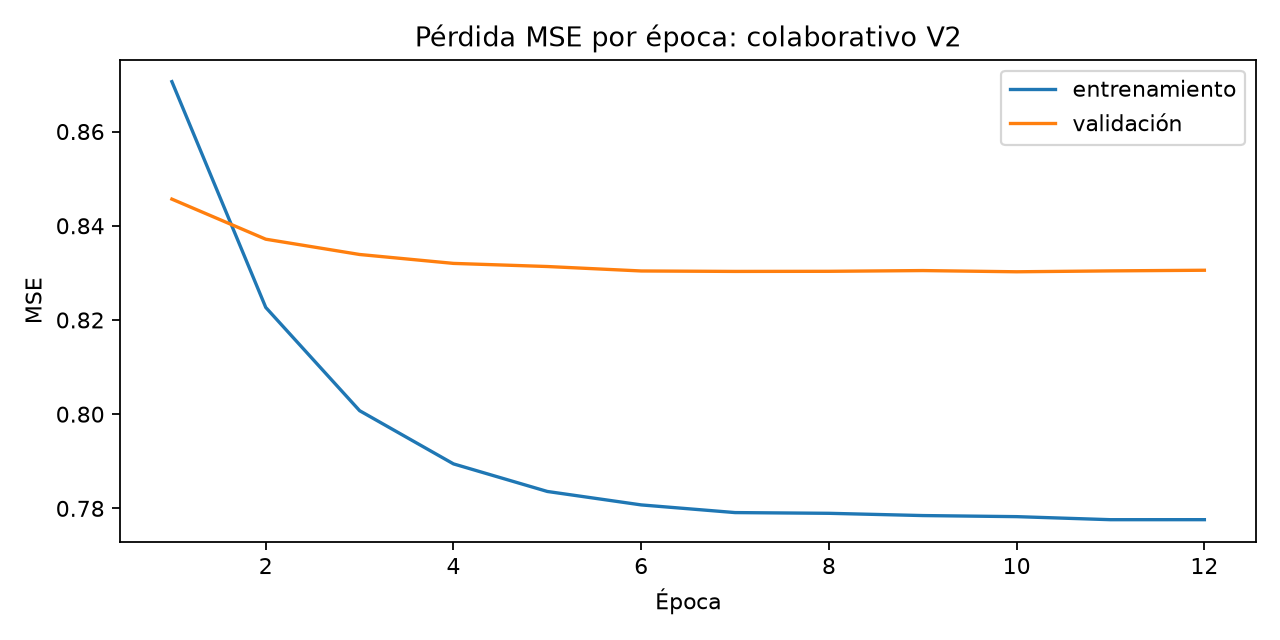

Recursos máximos: RSS 1.24 GiB; VRAM PyTorch 797 MiB; VRAM observada 2060 MiB.

In [3]:
from IPython.display import Image
display(Image(filename=ARTIFACTS / 'loss_curve.png'))
display(Markdown(f"Recursos máximos: RSS {metrics['epoch_resource_summary']['max_process_rss_bytes'] / 2**30:.2f} GiB; VRAM PyTorch {metrics['epoch_resource_summary']['max_peak_vram_allocated_bytes'] / 2**20:.0f} MiB; VRAM observada {metrics['epoch_resource_summary']['max_gpu_memory_mib']} MiB."))
